# Etapa 3 – Investigação dos dados e consultas SQL

## 1. Configuração

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson

pd.set_option("display.max_columns", 50)
pd.set_option("display.precision", 3)

DIR_PROC = Path("processado")

# Calendário: o que conta como "dia útil comum"
RECESSO = ("12-24", "01-06")   # recesso de fim de ano (mm-dd nas duas pontas)
EXCLUIR_PANDEMIA = False        # consulta da seção 5

# Seção 5
LARGURA_FAIXA = 2.0     # °C
MIN_DIAS_FAIXA = 20     # faixas com menos dias ficam fora da tabela e do gráfico
LIMIAR_CALOR = 25.0     # limiar de H1 na proposta: referência no gráfico da seção 5 e recorte do teste da seção 6

# Seção 6 (teste de H1)
LIMIARES_H1 = [23, 24, 25, 26, 27]   # °C, sensibilidade do resultado ao limiar
HAC_LAGS = 10                        # defasagens dos erros-padrão Newey-West (cerca de duas semanas de dias úteis)

# Cores (paleta categórica de referência em ordem fixa)
COR = ["#2a78d6", "#eb6834", "#1baf7a"]
TINTA, TINTA_2, GRADE = "#0b0b0b", "#52514e", "#e4e3df"
DIVERGENTE = LinearSegmentedColormap.from_list("azul_vermelho", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.figsize": (12, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "lines.markersize": 6, "legend.frameon": False,
})

con = duckdb.connect()

def sql(consulta):
    """Roda a consulta no DuckDB e devolve um DataFrame."""
    return con.sql(consulta).df()

## 2. Visões de apoio

In [2]:
con.sql(f"""
CREATE OR REPLACE VIEW diaria AS
SELECT * FROM read_parquet('{DIR_PROC / "base_diaria.parquet"}')
""")

con.sql(f"""
CREATE OR REPLACE VIEW diaria_cal AS
SELECT *,
       CASE
           WHEN fim_de_semana THEN 'fim de semana'
           WHEN feriado THEN 'feriado'
           WHEN strftime(data, '%m-%d') >= '{RECESSO[0]}'
             OR strftime(data, '%m-%d') <= '{RECESSO[1]}' THEN 'recesso'
           WHEN ponte THEN 'ponte'
           WHEN vespera_feriado THEN 'véspera'
           WHEN pos_feriado THEN 'pós-feriado'
           ELSE 'útil comum'
       END AS tipo_dia
FROM diaria
""")

sql("""
SELECT tipo_dia, COUNT(*) AS n_dias
FROM diaria_cal
GROUP BY tipo_dia
ORDER BY n_dias DESC
""")

,tipo_dia,n_dias
0,útil comum,2515
1,fim de semana,1148
2,feriado,118
3,recesso,94
4,véspera,63
5,pós-feriado,50
6,ponte,30


## 3. Cuidados com os dados

### 3.1 Tendência anual e dias quentes por ano

In [3]:
sql("""
SELECT ano,
       ROUND(AVG(carga_max) FILTER (WHERE tipo_dia = 'útil comum')) AS carga_max_media_uteis,
       COUNT(*) FILTER (WHERE tmax >= 28) AS dias_tmax_28_ou_mais,
       ROUND(AVG(tmax), 2) AS tmax_media,
       MAX(regime_ons) AS regime_ons_fim_do_ano,
       COUNT(*) FILTER (WHERE pandemia) AS dias_pandemia
FROM diaria_cal
GROUP BY ano
ORDER BY ano
""")

,ano,carga_max_media_uteis,dias_tmax_28_ou_mais,tmax_media,regime_ons_fim_do_ano,dias_pandemia
0,2015,13375.0,46,23.52,0,0
1,2016,13598.0,50,22.78,0,0
2,2017,13942.0,52,23.91,0,0
3,2018,14157.0,45,23.54,0,0
4,2019,14290.0,73,24.16,0,0
5,2020,14480.0,55,23.82,0,291
6,2021,15176.0,41,23.23,1,0
7,2022,15224.0,64,23.22,1,0
8,2023,16060.0,75,24.26,2,0
9,2024,17084.0,70,24.41,2,0


### 3.2 Carga de cada tipo de dia em relação ao dia útil comum do mesmo ano

In [4]:
sql("""
WITH ref AS (
    SELECT ano, AVG(carga_max) AS carga_ref
    FROM diaria_cal
    WHERE tipo_dia = 'útil comum' AND NOT dia_incompleto
    GROUP BY ano
)
SELECT tipo_dia,
       COUNT(*) AS n_dias,
       ROUND(AVG(d.carga_max / r.carga_ref), 3) AS carga_rel,
       ROUND(AVG(tmax), 1) AS tmax_media
FROM diaria_cal d
JOIN ref r USING (ano)
WHERE NOT dia_incompleto
GROUP BY tipo_dia
ORDER BY carga_rel
""")

,tipo_dia,n_dias,carga_rel,tmax_media
0,fim de semana,1148,0.847,23.8
1,feriado,118,0.864,24.8
2,ponte,30,0.902,23.5
3,recesso,94,0.914,28.0
4,véspera,63,0.958,22.9
5,pós-feriado,50,0.985,24.2
6,útil comum,2514,1.000,23.5


> **Interpretação**
>
> Tendência e calor andam juntos. A carga máxima média dos dias úteis comuns subiu de 13,4 GW em 2015 para 17,6 GW em 2025 (+32%). No mesmo período os dias com Tmax ≥ 28 °C passaram de 45–52 por ano (2015–2018) para 70–87 (2023–2025). Os maiores saltos de um ano para o outro ficam perto das trocas de regime do ONS: +4,8% em 2021 (troca em mar/2021, mas comparado com 2020, ano da pandemia), +5,5% em 2023 (troca em 29/04/2023) e +6,4% em 2024 (primeiro ano inteiro no regime 2), contra +0,3% a +3,2% nos outros anos. Comparar MWmed de anos diferentes atribuiria ao calor um aumento que vem do crescimento do consumo e da metodologia. Por isso as seções 4 e 5 dividem a carga pela média do próprio ano. Em 2020 a média anual não mostra a pandemia (ficou até acima de 2019), porque a queda se concentrou em poucos meses. Ela aparece no índice mensal da seção 4 (abr/2020).
>
> Os dias especiais têm carga menor, e o recesso e os feriados caem em dias quentes. Todos os tipos de dia especiais têm carga menor que o dia útil comum: fim de semana −15%, feriado −14%, ponte −10%, recesso −9%, véspera −4% e pós-feriado −1,5%. O recesso é o grupo mais quente (Tmax média de 28,0 °C, contra 23,5 °C nos dias úteis comuns), e os feriados também ficam acima da média (24,8 °C, por causa do Carnaval no verão). Se esses dias entrassem na seção 5, eles puxariam para baixo justamente as faixas mais quentes e achatariam o ramo de calor da curva. Por isso a seção 5 usa só dias úteis comuns, e a seção 4 mostra também o índice dos dias úteis.
>
> A diferença entre feriados e dias úteis (−14%) é uma primeira indicação a favor de H2, mas ainda sem controle de mês e dia da semana. O teste formal fica para a seção de hipóteses.

## 4. Sazonalidade mensal da carga e da temperatura

**Pergunta:** em quais meses o pico é mais alto? A sazonalidade da carga acompanha a da temperatura?

### 4.1 Índice por ano e mês (visão de apoio)

In [5]:
con.sql("""
CREATE OR REPLACE VIEW sazonal_ano_mes AS
WITH mensal AS (
    SELECT ano, mes,
           AVG(carga_max) AS carga_max_todos,
           AVG(carga_max) FILTER (WHERE tipo_dia = 'útil comum') AS carga_max_uteis,
           AVG(tmax) AS tmax,
           AVG(tmin) AS tmin
    FROM diaria_cal
    WHERE NOT dia_incompleto
    GROUP BY ano, mes
)
SELECT *,
       carga_max_todos / AVG(carga_max_todos) OVER (PARTITION BY ano) AS indice_todos,
       carga_max_uteis / AVG(carga_max_uteis) OVER (PARTITION BY ano) AS indice_uteis
FROM mensal
""")

sql("SELECT COUNT(*) AS n_ano_mes, COUNT(indice_uteis) AS n_com_dias_uteis FROM sazonal_ano_mes")

,n_ano_mes,n_com_dias_uteis
0,132,132


### 4.2 Resumo por mês

In [6]:
sazonal_mes = sql("""
SELECT mes,
       COUNT(*) AS n_anos,
       ROUND(AVG(carga_max_todos)) AS carga_max_media_mw,
       ROUND(MEDIAN(indice_todos), 3) AS indice_todos_mediana,
       ROUND(MIN(indice_todos), 3) AS indice_todos_min,
       ROUND(MAX(indice_todos), 3) AS indice_todos_max,
       ROUND(MEDIAN(indice_uteis), 3) AS indice_uteis_mediana,
       ROUND(AVG(tmax), 1) AS tmax_media,
       ROUND(AVG(tmin), 1) AS tmin_media,
       RANK() OVER (ORDER BY MEDIAN(indice_todos) DESC) AS posicao_carga,
       RANK() OVER (ORDER BY AVG(tmax) DESC) AS posicao_tmax
FROM sazonal_ano_mes
GROUP BY mes
ORDER BY mes
""")
sazonal_mes

,mes,n_anos,carga_max_media_mw,indice_todos_mediana,indice_todos_min,indice_todos_max,indice_uteis_mediana,tmax_media,tmin_media,posicao_carga,posicao_tmax
0,1,11,15021.0,1.060,1.006,1.119,1.102,28.0,20.3,2,1
1,2,11,15507.0,1.089,1.023,1.158,1.109,27.8,20.0,1,2
2,3,11,15010.0,1.057,1.009,1.115,1.052,26.7,19.2,3,4
3,4,11,13918.0,0.984,0.926,1.039,0.980,24.4,16.9,6,6
4,5,11,13647.0,0.955,0.942,0.990,0.939,21.3,13.8,12,9
5,6,11,13848.0,0.967,0.953,1.009,0.952,19.6,11.7,8,11
6,7,11,14015.0,0.980,0.947,1.019,0.961,19.4,10.9,7,12
7,8,11,13800.0,0.966,0.949,0.993,0.950,20.6,11.8,9,10
8,9,11,13668.0,0.961,0.940,0.982,0.951,22.4,14.0,10,8
9,10,11,13771.0,0.960,0.945,1.003,0.960,23.1,15.5,11,7


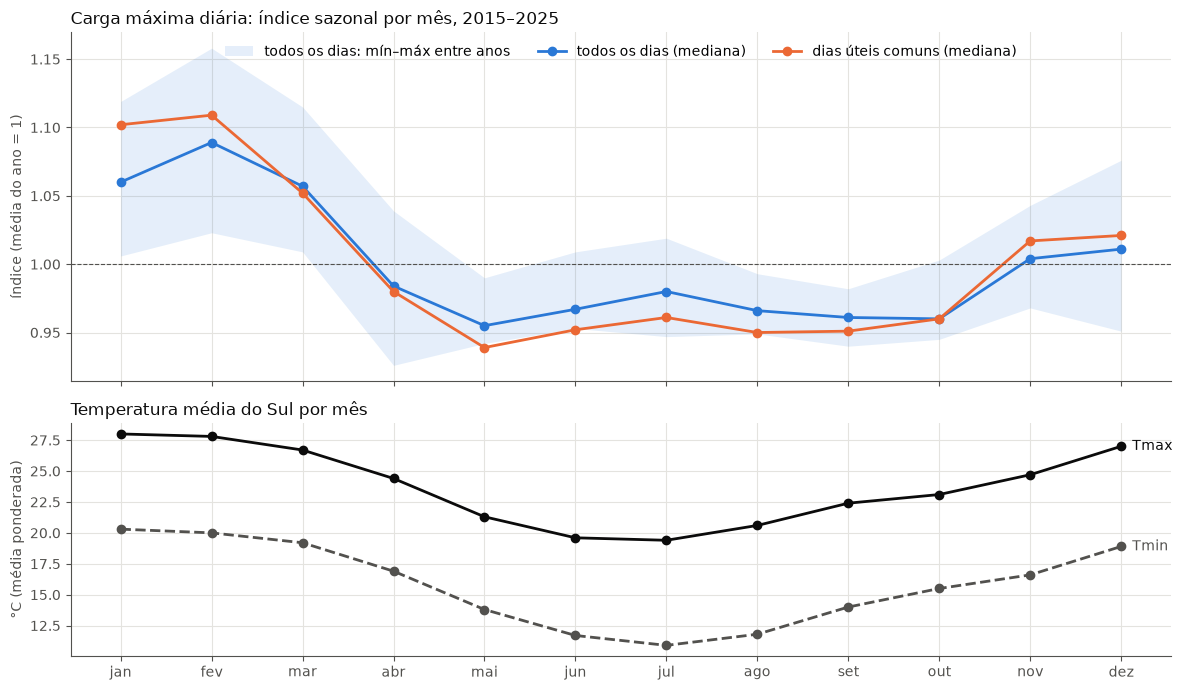

In [7]:
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
x = sazonal_mes["mes"]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, height_ratios=[3, 2])
ax1.fill_between(x, sazonal_mes["indice_todos_min"], sazonal_mes["indice_todos_max"],
                 color=COR[0], alpha=0.12, lw=0, label="todos os dias: mín–máx entre anos")
ax1.plot(x, sazonal_mes["indice_todos_mediana"], color=COR[0], marker="o", label="todos os dias (mediana)")
ax1.plot(x, sazonal_mes["indice_uteis_mediana"], color=COR[1], marker="o", label="dias úteis comuns (mediana)")
ax1.axhline(1, color=TINTA_2, lw=0.8, ls="--")
ax1.set_ylabel("índice (média do ano = 1)")
ax1.set_title("Carga máxima diária: índice sazonal por mês, 2015–2025", loc="left", color=TINTA)
ax1.legend(loc="upper center", ncols=3)

ax2.plot(x, sazonal_mes["tmax_media"], color=TINTA, marker="o")
ax2.plot(x, sazonal_mes["tmin_media"], color=TINTA_2, marker="o", ls="--")
ax2.annotate("Tmax", (12, sazonal_mes["tmax_media"].iloc[-1]), xytext=(8, 0), textcoords="offset points",
             va="center", color=TINTA)
ax2.annotate("Tmin", (12, sazonal_mes["tmin_media"].iloc[-1]), xytext=(8, 0), textcoords="offset points",
             va="center", color=TINTA_2)
ax2.set_ylabel("°C (média ponderada)")
ax2.set_title("Temperatura média do Sul por mês", loc="left", color=TINTA)
ax2.set_xticks(range(1, 13), MESES)
plt.tight_layout()

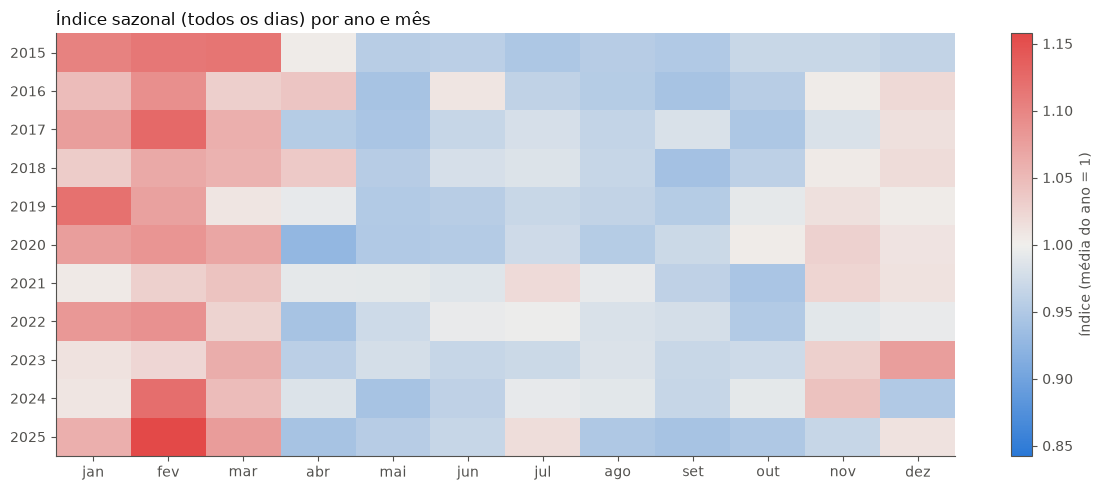

In [8]:
mapa = sql("SELECT ano, mes, indice_todos FROM sazonal_ano_mes").pivot(index="ano", columns="mes", values="indice_todos")
lim = float((mapa - 1).abs().max().max())

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(mapa, cmap=DIVERGENTE, norm=TwoSlopeNorm(1, 1 - lim, 1 + lim), aspect="auto")
ax.set_xticks(range(12), MESES)
ax.set_yticks(range(len(mapa)), mapa.index)
ax.grid(False)
ax.set_title("Índice sazonal (todos os dias) por ano e mês", loc="left", color=TINTA)
fig.colorbar(im, ax=ax, label="índice (média do ano = 1)")
plt.tight_layout()

> **Interpretação**
>
> A carga máxima tem dois patamares bem definidos. De dezembro a março ela fica acima da média do ano, com o pico em fevereiro (índice mediano de 1,089, cerca de 9% acima da média, e 15,5 GW em média). De abril a outubro ela fica cerca de 2% a 5% abaixo da média, com o mínimo em maio (0,955). Novembro é o mês de transição. A temperatura tem o mesmo desenho: os quatro meses de maior Tmax (jan, fev, dez, mar) são também os quatro de maior carga, e a correlação entre a mediana do índice de todos os dias (`indice_todos_mediana`) e a Tmax média (`tmax_media`) nos 12 meses é de 0,84. A sazonalidade da carga no Sul é comandada principalmente pelo calor do verão.
>
> A relação, porém, não é só linear. Julho é o mês mais frio (Tmax de 19,4 °C) e tem carga maior que maio, agosto, setembro e outubro (0,980, contra 0,955 a 0,966). Junho, quase tão frio, fica no nível desses meses (0,967). Esse pequeno pico de inverno em julho é compatível com o uso de aquecimento nos dias frios e é o primeiro sinal da forma em U testada em H3. O horário do pico também muda: nos dias úteis de verão o pico mais comum é às 14 h (ar-condicionado em comércio e serviços), e nos meses frios passa para 18–19 h (consumo residencial à noite).
>
> A curva dos dias úteis comuns tem amplitude maior que a de todos os dias (1,109 em fevereiro contra 0,939 em maio). Isso acontece porque a diferença entre fim de semana e dia útil muda ao longo do ano: no verão o fim de semana fica cerca de 18% abaixo do dia útil, e no inverno só 12% a 13%, provavelmente porque o pico residencial da noite depende menos do dia da semana. Em janeiro a distância entre as duas curvas é maior (1,060 contra 1,102) porque "todos os dias" incluem o recesso de fim de ano, de carga mais baixa. Ou seja, o efeito do dia da semana não é constante ao longo do ano.
>
> O mapa de calor mostra que o padrão se repete em todos os anos, com intensidade variável, e os desvios têm explicação conhecida:
> - fev/2025 é a célula mais alta (1,158) e é também o mês de maior Tmax média da série (30,0 °C);
> - dez/2023 (1,076) acompanha o calor do fim de 2023 (Tmax de 28,3 °C), enquanto dez/2024 (0,951) foi um dezembro mais ameno (26,0 °C);
> - abr/2020 é a célula mais baixa (0,926), o primeiro mês inteiro de isolamento da pandemia (as restrições começaram na segunda quinzena de março);
> - 2021 e o início de 2023 têm verões fracos no índice (jan–fev entre 1,006 e 1,029). Em parte, isso é um efeito do próprio índice: as mudanças de metodologia do ONS em mar/2021 e em 29/04/2023 elevaram a carga no resto desses anos, o que sobe a média anual e reduz o índice dos meses anteriores à mudança. O crescimento da carga dentro de cada ano tem um efeito parecido, mas menor, a favor dos últimos meses.
>
> O mês dá o padrão médio da carga, e a temperatura explica as diferenças entre anos que o mês sozinho não explica.

## 5. Carga máxima por faixa de temperatura máxima

**Pergunta:** qual é a carga máxima média em cada faixa de Tmax? A curva tem forma de U?

### 5.1 Dias úteis comuns com índice (visão de apoio)

In [9]:
con.sql(f"""
CREATE OR REPLACE VIEW uteis_indice AS
WITH base AS (
    SELECT data, ano, mes, regime_ons, tmax, carga_max
    FROM diaria_cal
    WHERE tipo_dia = 'útil comum'
      AND NOT dia_incompleto
      AND (NOT {EXCLUIR_PANDEMIA} OR ano NOT IN (SELECT DISTINCT ano FROM diaria WHERE pandemia))
),
ref_anual AS (
    SELECT ano, AVG(media_mes) AS carga_ref
    FROM (SELECT ano, mes, AVG(carga_max) AS media_mes FROM base GROUP BY ano, mes)
    GROUP BY ano
)
SELECT b.*,
       b.carga_max / r.carga_ref AS indice,
       FLOOR(b.tmax / {LARGURA_FAIXA}) * {LARGURA_FAIXA} AS faixa
FROM base b
JOIN ref_anual r USING (ano)
""")

sql("SELECT COUNT(*) AS n_dias, MIN(data) AS inicio, MAX(data) AS fim, list_sort(list(DISTINCT ano)) AS anos FROM uteis_indice")

,n_dias,inicio,fim,anos
0,2514,2015-01-07,2025-12-23,"[2015, 2016, 2017, 2018, 2019, 2020, 2021, 202..."


### 5.2 Índice por faixa de Tmax

In [10]:
faixas_tmax = sql(f"""
SELECT faixa AS faixa_ini,
       faixa + {LARGURA_FAIXA} AS faixa_fim,
       COUNT(*) AS n_dias,
       ROUND(AVG(carga_max)) AS carga_max_media_mw,
       ROUND(AVG(indice), 4) AS indice_medio,
       ROUND(1.96 * STDDEV_SAMP(indice) / SQRT(COUNT(*)), 4) AS ic95,
       ROUND(100 * (AVG(indice) - LAG(AVG(indice)) OVER (ORDER BY faixa)), 2) AS variacao_pp_vs_faixa_anterior
FROM uteis_indice
GROUP BY faixa
HAVING COUNT(*) >= {MIN_DIAS_FAIXA}
ORDER BY faixa
""")
faixas_tmax

,faixa_ini,faixa_fim,n_dias,carga_max_media_mw,indice_medio,ic95,variacao_pp_vs_faixa_anterior
0,12.0,14.0,36,14743.0,0.987,0.009,NaN
1,14.0,16.0,72,14670.0,0.973,0.008,-1.40
2,16.0,18.0,174,14292.0,0.955,0.005,-1.87
3,18.0,20.0,273,14083.0,0.946,0.004,-0.92
4,20.0,22.0,289,14163.0,0.945,0.003,-0.03
5,22.0,24.0,436,14388.0,0.958,0.003,1.27
6,24.0,26.0,450,14810.0,0.989,0.004,3.11
7,26.0,28.0,382,15588.0,1.040,0.006,5.11
8,28.0,30.0,271,16451.0,1.090,0.008,5.03
9,30.0,32.0,100,17909.0,1.149,0.013,5.85


### 5.3 A mesma curva em cada regime do ONS

In [11]:
faixas_regime = sql(f"""
SELECT faixa AS faixa_ini,
       COUNT(*) FILTER (WHERE regime_ons = 0) AS n_r0,
       COUNT(*) FILTER (WHERE regime_ons = 1) AS n_r1,
       COUNT(*) FILTER (WHERE regime_ons = 2) AS n_r2,
       CASE WHEN n_r0 >= {MIN_DIAS_FAIXA} THEN ROUND(AVG(indice) FILTER (WHERE regime_ons = 0), 4) END AS indice_r0,
       CASE WHEN n_r1 >= {MIN_DIAS_FAIXA} THEN ROUND(AVG(indice) FILTER (WHERE regime_ons = 1), 4) END AS indice_r1,
       CASE WHEN n_r2 >= {MIN_DIAS_FAIXA} THEN ROUND(AVG(indice) FILTER (WHERE regime_ons = 2), 4) END AS indice_r2
FROM uteis_indice
GROUP BY faixa
ORDER BY faixa
""")
faixas_regime

,faixa_ini,n_r0,n_r1,n_r2,indice_r0,indice_r1,indice_r2
0,10.0,4,3,3,NaN,NaN,NaN
1,12.0,20,9,7,0.970,NaN,NaN
2,14.0,37,14,21,0.959,NaN,0.978
3,16.0,101,33,40,0.942,0.980,0.967
4,18.0,148,69,56,0.934,0.967,0.948
5,20.0,161,59,69,0.936,0.966,0.949
6,22.0,250,71,115,0.959,0.972,0.947
7,24.0,260,81,109,0.998,0.979,0.975
8,26.0,231,65,86,1.051,1.020,1.026
9,28.0,148,63,60,1.109,1.059,1.079


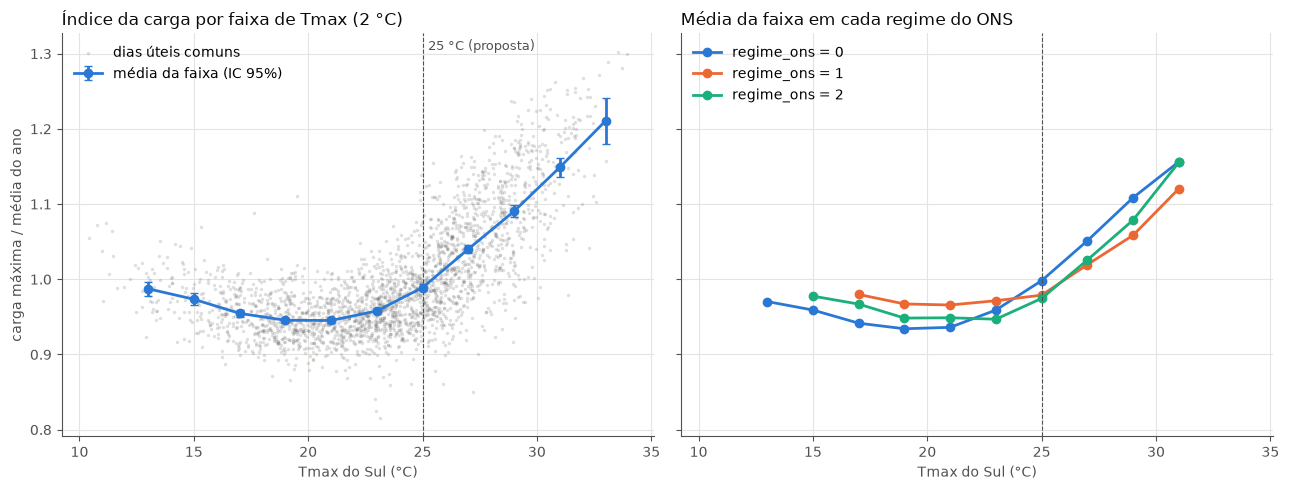

In [12]:
dias = sql("SELECT tmax, indice FROM uteis_indice")
centro = faixas_tmax["faixa_ini"] + LARGURA_FAIXA / 2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
ax1.scatter(dias["tmax"], dias["indice"], s=6, color=TINTA_2, alpha=0.18, lw=0, label="dias úteis comuns")
ax1.errorbar(centro, faixas_tmax["indice_medio"], yerr=faixas_tmax["ic95"], color=COR[0], marker="o",
             capsize=3, label="média da faixa (IC 95%)")
ax1.axvline(LIMIAR_CALOR, color=TINTA_2, lw=0.8, ls="--")
ax1.annotate(f"{LIMIAR_CALOR:.0f} °C (proposta)", (LIMIAR_CALOR, 1), xycoords=("data", "axes fraction"),
             xytext=(4, -12), textcoords="offset points", color=TINTA_2, fontsize=9)
ax1.set_xlabel("Tmax do Sul (°C)")
ax1.set_ylabel("carga máxima / média do ano")
ax1.set_title(f"Índice da carga por faixa de Tmax ({LARGURA_FAIXA:.0f} °C)", loc="left", color=TINTA)
ax1.legend(loc="upper left")

centro_r = faixas_regime["faixa_ini"] + LARGURA_FAIXA / 2
for r in range(3):
    ax2.plot(centro_r, faixas_regime[f"indice_r{r}"], color=COR[r], marker="o", label=f"regime_ons = {r}")
ax2.axvline(LIMIAR_CALOR, color=TINTA_2, lw=0.8, ls="--")
ax2.set_xlabel("Tmax do Sul (°C)")
ax2.set_title("Média da faixa em cada regime do ONS", loc="left", color=TINTA)
ax2.legend(loc="upper left")
plt.tight_layout()

> **Interpretação**
>
> Com só dias úteis comuns e com 2020 (2.514 dias), o efeito do calendário fica de fora e a curva mostra o efeito da temperatura. Ela tem forma de U assimétrico, o que apoia H3. O mínimo fica entre 18 °C e 22 °C (índice de 0,945, cerca de 5,5% abaixo da média do ano). Abaixo disso a carga volta a subir devagar: na faixa de 12–14 °C o índice é 0,987, 4,2 pontos percentuais (pp) acima do mínimo, uma diferença maior que os ICs de 95% das duas faixas. Acima de 22 °C a subida é muito mais rápida: 1,27 pp em 22–24 °C, depois de 3 a 6 pp a cada faixa de 2 °C, até 1,211 em 32–34 °C, 26 pp acima do mínimo. O ramo frio sobe cerca de 0,5 a 0,7 pp por °C, e o ramo quente cerca de 2,8 pp por °C (perto de 490 MW por °C no nível de carga de 2025).
>
> O limiar de 25 °C da proposta está bem colocado para H1. A curva começa a subir em 22–24 °C, mas é a partir de 24–26 °C que a subida fica forte e quase linear. No teste de H1, a regressão contra Tmax deve usar o índice (ou controlar o ano), porque a carga em MW mistura o efeito da temperatura com o crescimento anual. A nuvem de pontos também mostra que a dispersão aumenta nos dias quentes: com a mesma Tmax, a carga varia mais, o que sugere que outros fatores (umidade, sequência de dias quentes, chuva) também pesam.
>
> Separando por regime do ONS, o U aparece nos três períodos, então ele não é um artefato da mudança de metodologia. As diferenças estão nos detalhes:
> - no regime 0 (2015–2020 e jan–fev/2021) o vale é mais fundo (0,934) e a subida começa mais cedo, já em 22–24 °C;
> - nos regimes 1 e 2 o vale é mais raso (0,966 e 0,947) e a curva fica quase plana até 24–26 °C;
> - no ramo quente, o regime 1 fica abaixo dos outros (1,121 em 30–32 °C, contra cerca de 1,15).
>
> Essas diferenças vêm, em boa parte, do próprio índice. Os anos de 2021 e 2023 são cortados ao meio pelas mudanças de metodologia, e a média anual usada no índice mistura dois regimes. Os dias antes da mudança ficam com índice mais baixo e os dias depois, com índice mais alto. Os dias quentes de jan–abr/2023 são do regime 1 e vêm antes da mudança de 29/04, o que rebaixa o ramo quente desse regime. Já os meses de mai–dez/2023, quase todos fora do verão, são do regime 2 e levantam o seu vale. Tirando 2021 e 2023, os regimes 1 e 2 ficam praticamente iguais no ramo quente. O regime 1 também tem poucos dias nas faixas extremas (20 dias em 30–32 °C).

## 6. Teste de H1 – calor

**Hipótese:** em dias quentes (Tmax acima de `LIMIAR_CALOR`), a carga máxima aumenta com a Tmax. H0: inclinação ≤ 0; H1: inclinação > 0.

### 6.1 Amostra

In [13]:
amostra_h1 = sql(f"""
SELECT data, ano, regime_ons, tmax, indice, carga_max
FROM uteis_indice
WHERE tmax > {LIMIAR_CALOR}
ORDER BY data
""")

sql(f"""
SELECT COUNT(*) AS n_dias,
       COUNT(DISTINCT ano) AS n_anos,
       ROUND(MIN(tmax), 1) AS tmax_min,
       ROUND(MAX(tmax), 1) AS tmax_max,
       ROUND(AVG(indice), 3) AS indice_medio
FROM uteis_indice
WHERE tmax > {LIMIAR_CALOR}
""")

,n_dias,n_anos,tmax_min,tmax_max,indice_medio
0,1010,11,25.0,33.9,1.058


### 6.2 Regressão da carga contra a Tmax

In [14]:
def regressao_h1(dados, y="indice", controles=None):
    """MQO de y contra tmax com erros-padrão HAC (Newey-West). Teste unilateral de H0: inclinação <= 0."""
    X = dados[["tmax"]] if controles is None else dados[["tmax"]].join(controles)
    ajuste = sm.OLS(dados[y], sm.add_constant(X)).fit(cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS})
    ic = ajuste.conf_int().loc["tmax"]
    return ajuste, {
        "n_dias": int(ajuste.nobs),
        "inclinacao": ajuste.params["tmax"],
        "ic95_inf": ic.iloc[0],
        "ic95_sup": ic.iloc[1],
        "p_unilateral": stats.norm.sf(ajuste.tvalues["tmax"]),
        "r2": ajuste.rsquared,
        "durbin_watson": durbin_watson(ajuste.resid),
    }

ajuste_h1, res_indice = regressao_h1(amostra_h1)
efeito_ano = pd.get_dummies(amostra_h1["ano"], prefix="ano", drop_first=True, dtype=float)
_, res_mw = regressao_h1(amostra_h1, y="carga_max", controles=efeito_ano)

resultado_h1 = pd.DataFrame({
    "índice (pp por °C)": res_indice,
    "MWmed com efeito fixo de ano (MW por °C)": res_mw,
}).T
resultado_h1.loc["índice (pp por °C)", ["inclinacao", "ic95_inf", "ic95_sup"]] *= 100
resultado_h1.style.format({"n_dias": "{:.0f}", "inclinacao": "{:.2f}", "ic95_inf": "{:.2f}", "ic95_sup": "{:.2f}",
                           "p_unilateral": "{:.1e}", "r2": "{:.3f}", "durbin_watson": "{:.2f}"})

,n_dias,inclinacao,ic95_inf,ic95_sup,p_unilateral,r2,durbin_watson
índice (pp por °C),1010,2.84,2.52,3.15,3.9e-71,0.463,0.50
MWmed com efeito fixo de ano (MW por °C),1010,455.00,408.21,501.79,2.7e-81,0.792,0.61


### 6.3 Sensibilidade ao limiar e aos regimes do ONS

In [15]:
linhas = []
for limiar in LIMIARES_H1:
    dados = sql(f"SELECT tmax, indice FROM uteis_indice WHERE tmax > {limiar} ORDER BY data")
    linhas.append({"recorte": f"Tmax > {limiar} °C", **regressao_h1(dados)[1]})
for r in range(3):
    dados = sql(f"SELECT tmax, indice FROM uteis_indice WHERE tmax > {LIMIAR_CALOR} AND regime_ons = {r} ORDER BY data")
    linhas.append({"recorte": f"Tmax > {LIMIAR_CALOR:.0f} °C, regime_ons = {r}", **regressao_h1(dados)[1]})

sensibilidade_h1 = pd.DataFrame(linhas).set_index("recorte")
sensibilidade_h1[["inclinacao", "ic95_inf", "ic95_sup"]] *= 100   # pp por °C
sensibilidade_h1.style.format({"n_dias": "{:.0f}", "inclinacao": "{:.2f}", "ic95_inf": "{:.2f}", "ic95_sup": "{:.2f}",
                               "p_unilateral": "{:.1e}", "r2": "{:.3f}", "durbin_watson": "{:.2f}"})

,n_dias,inclinacao,ic95_inf,ic95_sup,p_unilateral,r2,durbin_watson
recorte,,,,,,,
Tmax > 23 °C,1463,2.58,2.37,2.79,5.1e-130,0.566,0.57
Tmax > 24 °C,1224,2.74,2.49,2.99,3.8e-102,0.518,0.52
Tmax > 25 °C,1010,2.84,2.52,3.15,3.9e-71,0.463,0.50
Tmax > 26 °C,774,2.83,2.45,3.21,2.1e-48,0.385,0.51
Tmax > 27 °C,551,2.93,2.44,3.43,7.4e-32,0.315,0.56
"Tmax > 25 °C, regime_ons = 0",573,2.94,2.52,3.37,1.8e-42,0.428,0.45
"Tmax > 25 °C, regime_ons = 1",194,2.64,2.04,3.25,4.4e-18,0.594,0.73
"Tmax > 25 °C, regime_ons = 2",243,3.08,2.51,3.66,2.9e-26,0.590,0.81


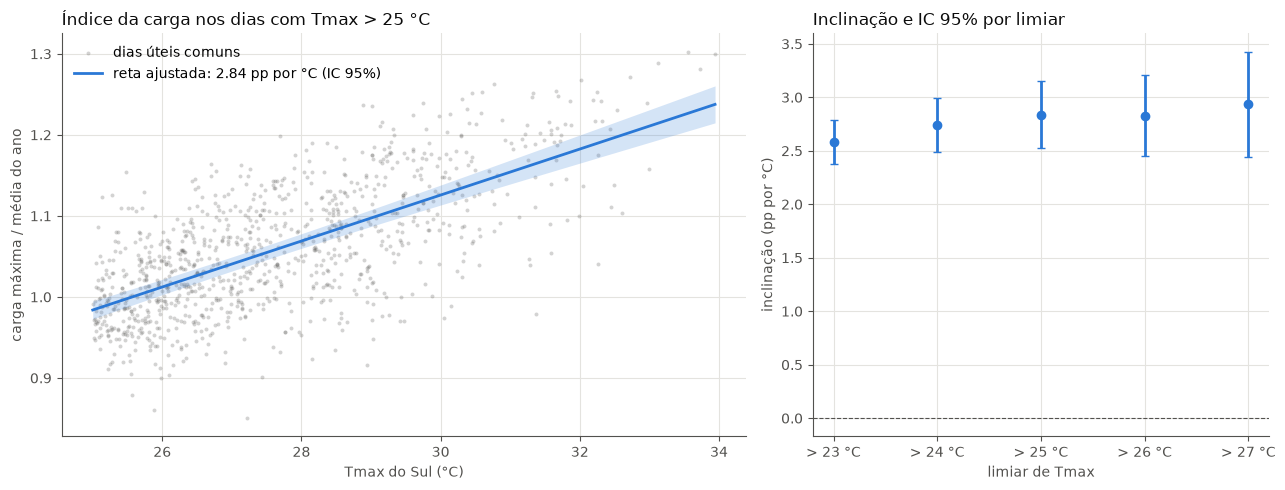

In [16]:
grade = pd.DataFrame({"tmax": np.linspace(amostra_h1["tmax"].min(), amostra_h1["tmax"].max(), 50)})
previsao = ajuste_h1.get_prediction(sm.add_constant(grade, has_constant="add")).summary_frame(alpha=0.05)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), width_ratios=[3, 2])
ax1.scatter(amostra_h1["tmax"], amostra_h1["indice"], s=8, color=TINTA_2, alpha=0.25, lw=0, label="dias úteis comuns")
ax1.fill_between(grade["tmax"], previsao["mean_ci_lower"], previsao["mean_ci_upper"], color=COR[0], alpha=0.2, lw=0)
ax1.plot(grade["tmax"], previsao["mean"], color=COR[0],
         label=f"reta ajustada: {100 * ajuste_h1.params['tmax']:.2f} pp por °C (IC 95%)")
ax1.set_xlabel("Tmax do Sul (°C)")
ax1.set_ylabel("carga máxima / média do ano")
ax1.set_title(f"Índice da carga nos dias com Tmax > {LIMIAR_CALOR:.0f} °C", loc="left", color=TINTA)
ax1.legend(loc="upper left")

lim = sensibilidade_h1.iloc[:len(LIMIARES_H1)]
ax2.errorbar(LIMIARES_H1, lim["inclinacao"], yerr=[lim["inclinacao"] - lim["ic95_inf"], lim["ic95_sup"] - lim["inclinacao"]],
             color=COR[0], marker="o", capsize=3, ls="none")
ax2.axhline(0, color=TINTA_2, lw=0.8, ls="--")
ax2.set_xticks(LIMIARES_H1, [f"> {l} °C" for l in LIMIARES_H1])
ax2.set_xlabel("limiar de Tmax")
ax2.set_ylabel("inclinação (pp por °C)")
ax2.set_title("Inclinação e IC 95% por limiar", loc="left", color=TINTA)
plt.tight_layout()

> **Interpretação**
>
> Nos 1.010 dias úteis comuns com Tmax acima de 25 °C (11 anos, 2015–2025), a carga máxima sobe 2,84 pp da média do ano a cada °C a mais de Tmax (IC 95% de 2,52 a 3,15 pp por °C). O p-valor unilateral é praticamente zero (3,9e-71), então H0 é rejeitada: os dados sustentam H1. Em MWmed, com efeito fixo de ano, a inclinação é de 455 MW por °C (IC 95% de 408 a 502). Esse valor é uma média entre os anos e fica um pouco abaixo dos cerca de 490 MW por °C da seção 5, que usam o nível de carga de 2025.
>
> O Durbin-Watson de 0,50 mostra que os resíduos de dias próximos são fortemente correlacionados: ondas de calor duram vários dias, e os dias de uma mesma onda não são observações independentes. Por isso os ICs usam erros-padrão de Newey-West, que ficam mais largos que os da regressão comum. Mesmo assim, o intervalo fica longe de zero. O R² de 0,46 indica que a Tmax explica cerca de metade da variação do índice nos dias quentes; o restante vem de outros fatores, o que combina com a dispersão crescente vista na seção 5.
>
> O resultado não depende do limiar de 25 °C. Entre 23 °C e 27 °C, a inclinação vai de 2,58 a 2,93 pp por °C, e todos os ICs se sobrepõem e excluem o zero. A inclinação cresce um pouco com o limiar porque os limiares mais baixos incluem o início da curva, onde a subida é mais lenta (1,27 pp na faixa de 22–24 °C). O efeito também aparece nos três regimes do ONS (2,94, 2,64 e 3,08 pp por °C), com ICs que se sobrepõem. O valor menor do regime 1 está dentro do IC dos outros e pode vir do efeito do índice em jan–abr/2023, descrito na seção 5.
>
> Para a previsão de D+1, isso significa que a temperatura é um preditor forte nos dias quentes, mas a Tmax observada em D+1 não pode ser usada como atributo, porque só é conhecida depois. Com uma inclinação de cerca de 2,8 pp por °C, um erro de 1 °C na temperatura usada no modelo vira um erro de quase 3% na carga máxima prevista. Os modelos terão de usar a Tmax de D ou previsões meteorológicas emitidas em D.